# Controlled supervised contrastive learning with fixed P1

C0 is the unchanged 16,897-parameter profile/behavioral + temporal-statistics + frozen multilingual XLM-R model. C1 adds a training-only 80→32→ReLU→16 projection head and L2 normalization. Both use the same 80-dimensional concatenated representation and unchanged classifier. C1 has 20,017 training parameters and 16,897 inference parameters.

Use paired seeds 42/43/44, all 671 training users and 144 validation users, 50 epochs, batch 32, AdamW lr 0.001 and weight decay 0.0001, positive BCE weight 540/131, threshold 0.5. Select the earliest minimum unweighted validation BCE and preserve final checkpoints. P1 is the approved development reference, not a promoted final model.

SupCon uses temperature 0.1 and lambda 0.05. Two views use existing branch dropout only. Positives are other same-label views; negatives are opposite-label views. Average positive log probabilities per anchor, then average the two class-anchor means equally. Single-class batches retain BCE and have zero contrastive loss. No resampling or dropped users.

The primary forward is unchanged and supplies the only classification loss. Auxiliary RNG and head initialization are isolated. Auxiliary BatchNorm uses minibatch statistics without updating running buffers/counters. A lambda=0 regression must exactly reproduce primary logits, updates, buffers and RNG on one complete training epoch per seed before the six experiment runs.

No test access, language-model inference/fine-tuning, graphs, gating, pseudo-labels, feature noise, text changes or modality dropout. Validation never participates in contrastive pairs. The later modality study is not part of this notebook.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/contrastive_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.contrastive import run, verify
output_dir = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
print(verify(ROOT, output_dir))

OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\contrastive_v1\20260928T051235934399Z_41464a56


PASS: lambda=0 exact logits, state/BN buffers, and primary RNG for 21 updates per seed


C0 seed 42 epoch 25: validation BCE 0.635387


C0 seed 42 epoch 50: validation BCE 0.715135


C1 seed 42 epoch 25: validation BCE 0.637386


...

C0 seed 44 epoch 50: validation BCE 0.534411


C1 seed 44 epoch 25: validation BCE 0.547378


C1 seed 44 epoch 50: validation BCE 0.542921


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\contrastive_v1\20260928T051235934399Z_41464a56


{'training_runs': 6, 'selected_final_checkpoints_reloaded': 12, 'initial_snapshots_reloaded': 6, 'keyed_predictions_reproduced': 12, 'representation_arrays_reproduced': 72, 'lambda_zero_regression': [{'seed': 42, 'steps': 21, 'atol': 0.0, 'rtol': 0.0, 'max_logit_difference': 0.0, 'state_including_bn_exact': True, 'primary_rng_exact': True, 'head_rng_isolated': True}, {'seed': 43, 'steps': 21, 'atol': 0.0, 'rtol': 0.0, 'max_logit_difference': 0.0, 'state_including_bn_exact': True, 'primary_rng_exact': True, 'head_rng_isolated': True}, {'seed': 44, 'steps': 21, 'atol': 0.0, 'rtol': 0.0, 'max_logit_difference': 0.0, 'state_including_bn_exact': True, 'primary_rng_exact': True, 'head_rng_isolated': True}], 'historical_P1_C0_states_exact': True, 'primary_rng_and_batches_paired': True, 'test_access': False, 'consistent_development_improvement': False, 'promoted_model': None}


## Validation results and fixed decision rule

C1 is a consistent development improvement only if selected-checkpoint all-user Bot F1 improves in all three paired seeds, mean AP does not decrease, and verification passes. No automatic promotion. These are reused-validation development results, not statistical proof or new test results. Report selected and final checkpoints, precision/recall trade-offs, ranking, calibration and all cohorts.

,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std,validation_unweighted_loss_mean,validation_unweighted_loss_std
2,C0,best_unweighted_validation_loss,all,0.494172,0.028423,0.402980,0.038937,0.642857,0.035714,0.756671,0.006620,0.548662,0.016240,0.177880,0.015646,0.541210,0.022535
7,C0,last,all,0.460989,0.081045,0.375882,0.092667,0.607143,0.035714,0.737890,0.027935,0.520536,0.022614,0.192516,0.037245,0.606176,0.095931
12,C1,best_unweighted_validation_loss,all,0.482692,0.025619,0.387319,0.029774,0.642857,0.035714,0.755747,0.005852,0.540540,0.003452,0.180416,0.012328,0.543888,0.018754
17,C1,last,all,0.467821,0.054251,0.384017,0.072524,0.607143,0.000000,0.736145,0.022714,0.528337,0.040501,0.191309,0.030519,0.607356,0.075922


,seed,policy,cohort,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier,delta_validation_unweighted_loss
0,42,best_unweighted_validation_loss,all,-0.005842,-0.007059,0.000000,0.000616,0.006050,-0.001164,-0.002892
5,42,last,all,0.046818,0.043628,0.035714,0.005234,0.009810,-0.009729,-0.024081
10,43,best_unweighted_validation_loss,all,-0.006847,-0.008788,0.000000,-0.006773,-0.010480,0.003500,0.010060
15,43,last,all,-0.034247,-0.031313,-0.035714,-0.010160,-0.011024,0.004514,0.019109
20,44,best_unweighted_validation_loss,all,-0.021748,-0.031136,0.000000,0.003387,-0.019935,0.005274,0.000869
25,44,last,all,0.007925,0.012091,0.000000,-0.000308,0.024616,0.001594,0.008510


{
  "criterion_metrics_pass": false,
  "all_three_f1_improved": false,
  "mean_delta_f1": -0.011479168902180426,
  "mean_delta_ap": -0.008121874077708443,
  "requires_independent_verification": true,
  "promoted_model": null,
  "interpretation": "development_only_not_statistical_proof"
}



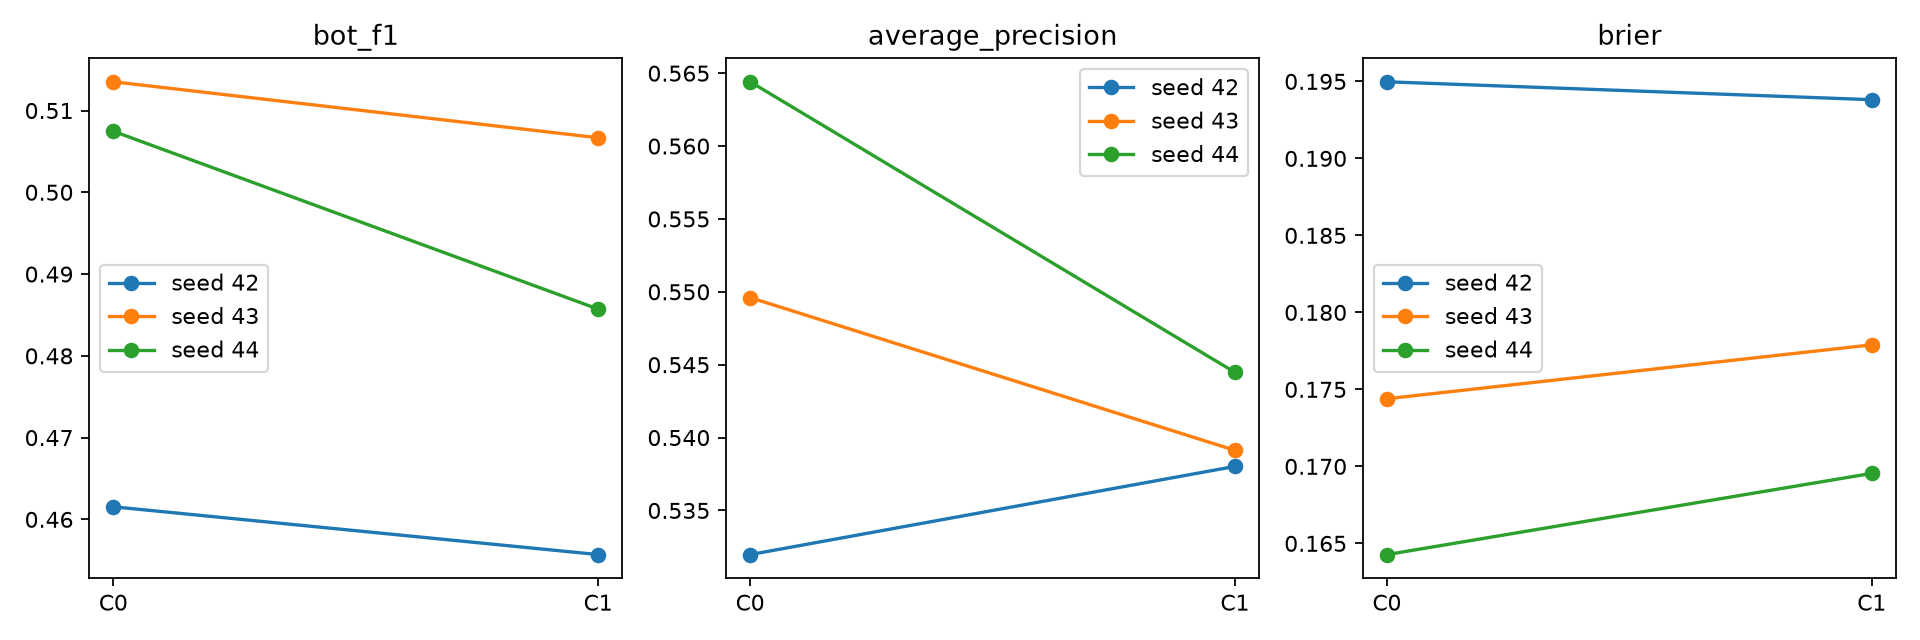

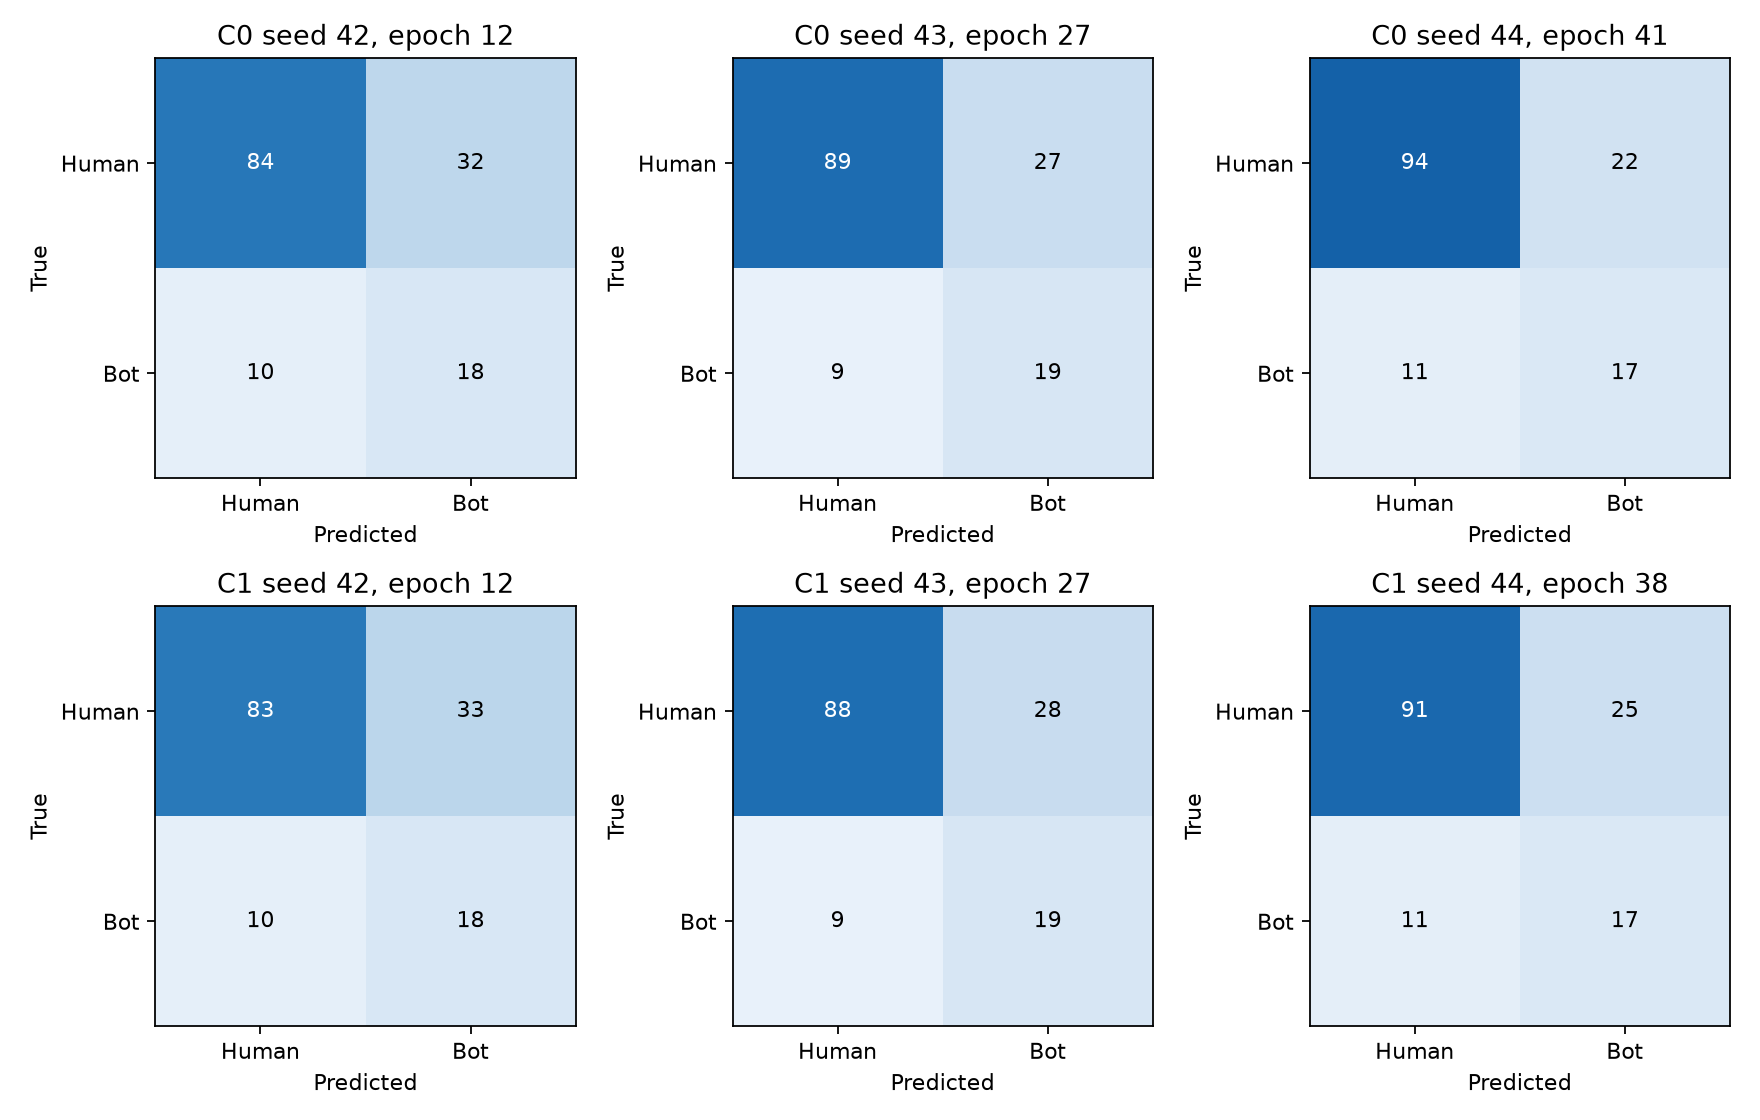

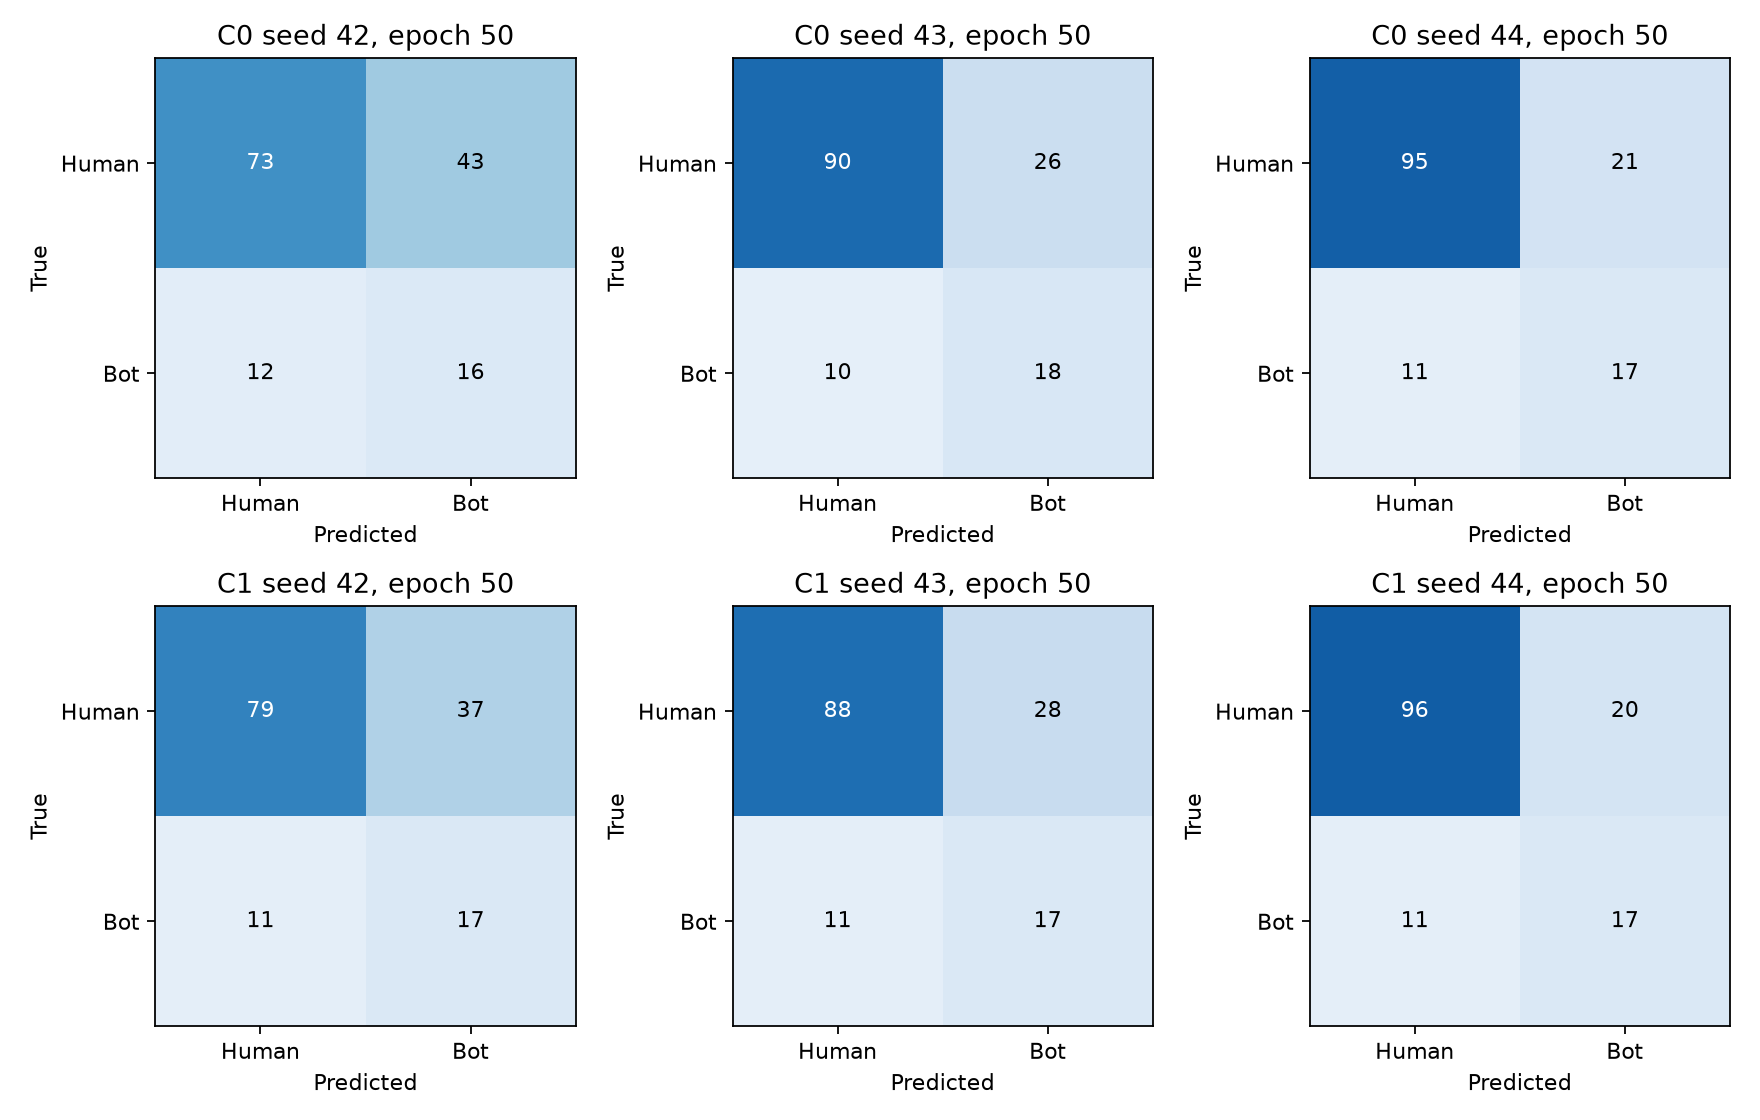

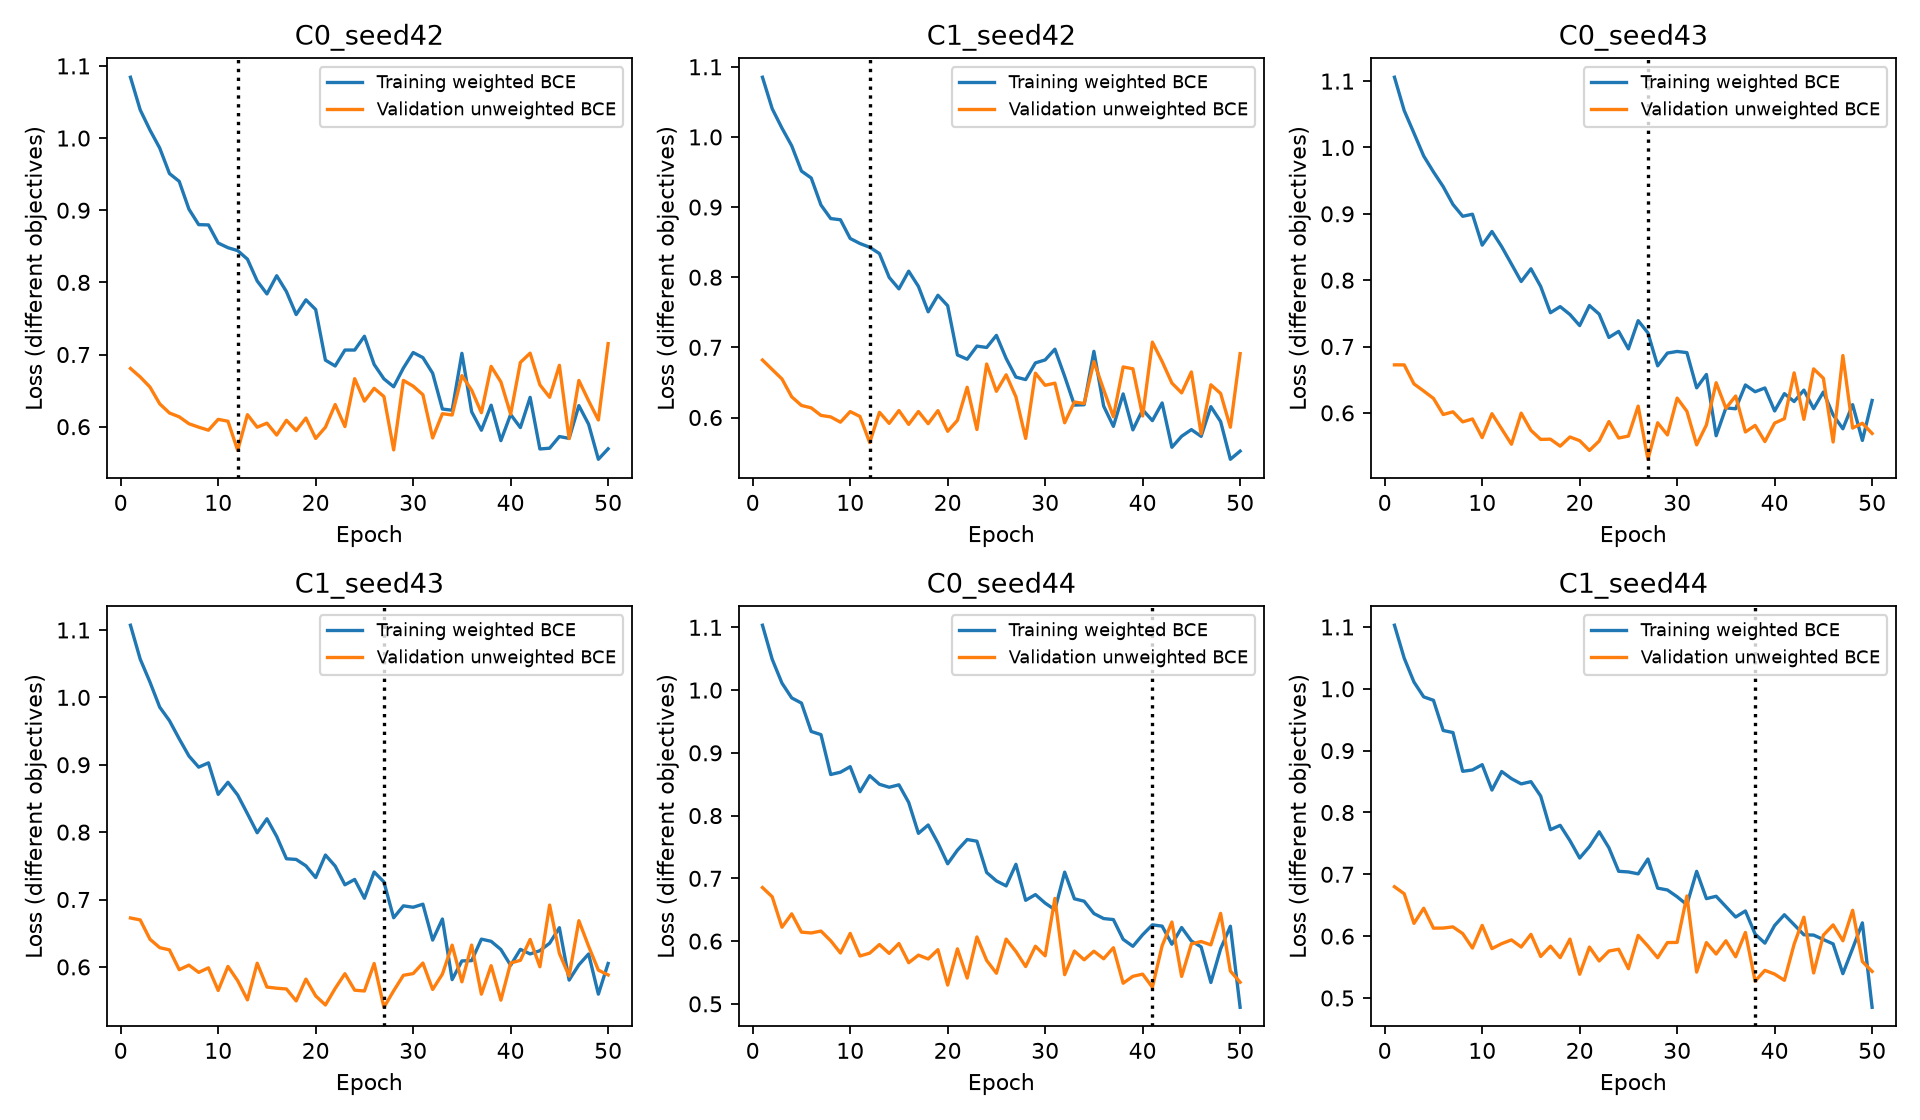

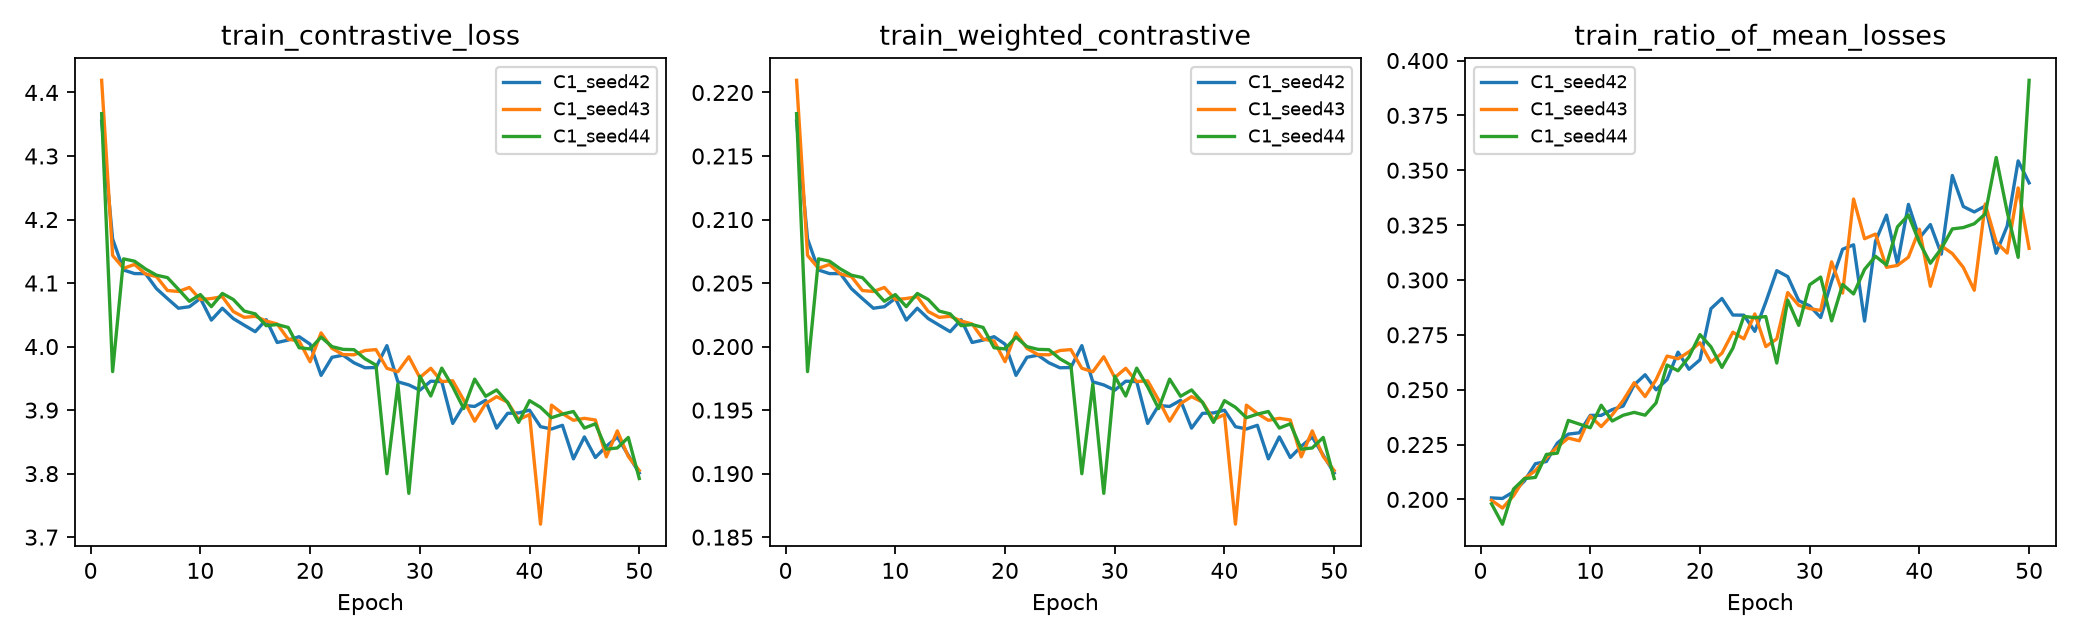

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
summary = pd.read_csv(output_dir / 'seed_summary.csv')
effects = pd.read_csv(output_dir / 'paired_effects.csv')
display(summary[summary.cohort.eq('all')])
display(effects[effects.cohort.eq('all')])
print((output_dir / 'development_decision.json').read_text())
for name in ['paired_metrics', 'confusion_selected', 'confusion_final', 'classification_curves', 'contrastive_curves']:
    display(Image(filename=str(output_dir / 'figures' / (name + '.png'))))

## Representation diagnostics: training and validation kept separate

At initialization, selected checkpoint and final checkpoint, export fused 80-dimensional representations for both arms and raw/normalized projections for C1. Save keyed arrays, population variance per coordinate, centered covariance eigenvalues/effective rank, zero/inactive rates, norms, same-class compactness and between-class separation. Effective rank is exp(entropy of normalized centered covariance eigenvalues). Zero-vector norm threshold is 1e-12; near-constant coordinate SD threshold is 1e-6. These thresholds are descriptive, not model-selection rules. A lower within-class rank does not by itself establish harmful global collapse.

Same-user dropout-view diagnostics use the first 32 canonical training rows only, copied models and isolated RNG. Validation representations are deterministic evaluation outputs, never training pairs. Current train/validation users have observed text/temporal modalities, so functional missingness tests do not establish empirical missing-modality robustness. Equal-class anchor reduction does not completely correct denominator imbalance.

In [3]:
diagnostics = pd.read_csv(output_dir / 'representation_diagnostics.csv')
columns = ['run','policy','space','effective_rank','total_variance','zero_vector_rate','inactive_coordinate_rate','balanced_within_scatter','centroid_distance','separation_over_scatter','between_class_cosine']
for split in ['train','validation']:
    print('DIAGNOSTIC SPLIT:', split)
    display(diagnostics[diagnostics.split.eq(split)][columns])
print('LAMBDA ZERO REGRESSION')
print((output_dir / 'lambda_zero_regression.json').read_text())
print('RUNTIME')
print((output_dir / 'runtime.json').read_text())

DIAGNOSTIC SPLIT: train


,run,policy,space,effective_rank,total_variance,zero_vector_rate,inactive_coordinate_rate,balanced_within_scatter,centroid_distance,separation_over_scatter,between_class_cosine
0,C0_seed42,initial,fused,16.047834,3.742747,0.0,0.0875,3.614872,0.703549,0.136929,0.579132
2,C0_seed42,best_unweighted_validation_loss,fused,21.196831,18.855005,0.0,0.1375,18.120245,2.115979,0.247092,0.381950
4,C0_seed42,last,fused,23.757077,19.487021,0.0,0.1625,18.602017,2.013451,0.217933,0.315773
6,C1_seed42,initial,fused,16.047834,3.742747,0.0,0.0875,3.614872,0.703549,0.136929,0.579132
7,C1_seed42,initial,projection_raw,7.686821,0.035138,0.0,0.0000,0.033533,0.061958,0.114477,0.879452
8,C1_seed42,initial,projection_normalized,7.672525,0.114823,0.0,0.0000,0.113650,0.117457,0.121392,0.879452
12,C1_seed42,best_unweighted_validation_loss,fused,21.253575,18.750005,0.0,0.1250,17.959618,2.107819,0.247383,0.380274
13,C1_seed42,best_unweighted_validation_loss,projection_raw,3.914576,0.486061,0.0,0.0000,0.417140,0.707377,1.199553,0.919077
14,C1_seed42,best_unweighted_validation_loss,projection_normalized,4.988638,0.067487,0.0,0.0000,0.046150,0.263716,1.506978,0.919077
18,C1_seed42,last,fused,24.344010,19.363010,0.0,0.1375,18.451299,2.015773,0.220220,0.312794


DIAGNOSTIC SPLIT: validation


,run,policy,space,effective_rank,total_variance,zero_vector_rate,inactive_coordinate_rate,balanced_within_scatter,centroid_distance,separation_over_scatter,between_class_cosine
1,C0_seed42,initial,fused,14.820443,3.653346,0.0,0.1125,3.584702,0.781486,0.170368,0.591131
3,C0_seed42,best_unweighted_validation_loss,fused,19.282776,18.730042,0.0,0.1625,19.060396,1.844931,0.178578,0.396030
5,C0_seed42,last,fused,22.486309,18.668934,0.0,0.1750,19.092079,1.473557,0.113731,0.338608
9,C1_seed42,initial,fused,14.820443,3.653346,0.0,0.1125,3.584702,0.781486,0.170368,0.591131
10,C1_seed42,initial,projection_raw,7.011191,0.033180,0.0,0.0000,0.031757,0.063173,0.125669,0.883406
11,C1_seed42,initial,projection_normalized,7.174068,0.110880,0.0,0.0000,0.109890,0.115799,0.122025,0.883406
15,C1_seed42,best_unweighted_validation_loss,fused,19.412560,18.550872,0.0,0.1375,18.904975,1.842595,0.179591,0.394882
16,C1_seed42,best_unweighted_validation_loss,projection_raw,3.112481,0.558965,0.0,0.0000,0.618207,0.599257,0.580889,0.924894
17,C1_seed42,best_unweighted_validation_loss,projection_normalized,4.543274,0.068328,0.0,0.0000,0.059073,0.179070,0.542818,0.924894
21,C1_seed42,last,fused,23.091646,18.584873,0.0,0.1375,18.942442,1.496288,0.118194,0.338866


LAMBDA ZERO REGRESSION
[
  {
    "seed": 42,
    "steps": 21,
    "atol": 0.0,
    "rtol": 0.0,
    "max_logit_difference": 0.0,
    "state_including_bn_exact": true,
    "primary_rng_exact": true,
    "head_rng_isolated": true
  },
  {
    "seed": 43,
    "steps": 21,
    "atol": 0.0,
    "rtol": 0.0,
    "max_logit_difference": 0.0,
    "state_including_bn_exact": true,
    "primary_rng_exact": true,
    "head_rng_isolated": true
  },
  {
    "seed": 44,
    "steps": 21,
    "atol": 0.0,
    "rtol": 0.0,
    "max_logit_difference": 0.0,
    "state_including_bn_exact": true,
    "primary_rng_exact": true,
    "head_rng_isolated": true
  }
]

RUNTIME
{
  "training_seconds": 63.345355900004506,
  "training_export_diagnostics_seconds": 70.21428430010565,
  "peak_sampled_process_rss_bytes": 519454720,
  "native_peak_working_set_bytes": 519454720,
  "sampling_interval_seconds": 0.05
}

